## ISOM4030 Lab 3 (Part 2) - Logistic Regression for Classification

In [5]:
# If you want to enable matplotlib's interactive features
# install jupyter-matplotlib (a.k.a. ipympl) via pip or conda.
! pip install ipympl --quiet

Restart runtime to continue. Upload the *lab4_utils.py* file to the virtual machine.

In [6]:
from google.colab import output
output.enable_custom_widget_manager()

# Enable the widget backend.

%matplotlib widget

In [ ]:
import matplotlib as mpl
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')

import pandas as pd
import numpy as np

from lab3_2_utils import plt_logistic_squared_error, plt_logistic_cost, plt_quad_logistic

%config InlineBackend.figure_format="retina"

## Sigmoid or Logistic Function

As discussed in lectures, for a binary classification task, we can start by using our linear regression model, $f_{\mathbf{w},b}(\mathbf{x}^{(i)}) = \mathbf{w} \cdot  \mathbf{x}^{(i)} + b$, to predict $y$ given $\mathbf{x}^{(i)}$.
- However, we would like the predictions of our classification model to be between 0 and 1 since our output variable $y$ is either 0 or 1.
- This can be accomplished by using a "sigmoid function" which maps all input values to values between 0 and 1.


Let's implement the sigmoid function and see this for ourselves.

## Formula for Sigmoid function

The formula for a sigmoid function is as follows -  

$\sigma(z) = \frac{1}{1+e^{-z}}\tag{1}$

In the case of logistic regression, $z$ (the input to the sigmoid function), is the output of a linear regression model.
- In the case of a single example, $z$ is scalar.
- in the case of multiple examples, $z$ may be a vector consisting of $m$ values, one for each example.
- The implementation of the sigmoid function should cover both of these potential input formats.

NumPy has a function called [`np.exp()`](https://numpy.org/doc/stable/reference/generated/numpy.exp.html), which offers a convenient way to calculate the exponential ( $e^{z}$) of all elements in the input array (`z`).


**<font color='steelblue' > Question 1</font>**:

Complete the following code to implement the sigmoid function in Python.

In [8]:
def sigmoid(z):
    """
    Compute the sigmoid of z

    Args:
        z (ndarray): A scalar, numpy array of any size.

    Returns:
        sigma (ndarray): sigmoid(z), with the same shape as z

    """

    # start your code here




    # end your code here

## Logistic Regression

A logistic regression model applies the sigmoid to the familiar linear regression model as shown below:

$$ f_{\mathbf{w},b}(\mathbf{x}^{(i)}) = \sigma(\mathbf{w} \cdot \mathbf{x}^{(i)} + b ) \tag{2} $$

  where

  $\sigma(z) = \frac{1}{1+e^{-z}}\tag{3}$

Let's apply logistic regression to the categorical data example of tumor classification.  


In [9]:
# a one-feature training set
x_train_1 = np.array([0, 1, 2, 3, 4, 5])
y_train_1 = np.array([0, 0, 0, 1, 1, 1])

**<font color='steelblue' > Question 2</font>**:

Complete the following code to generate a plot as follows.

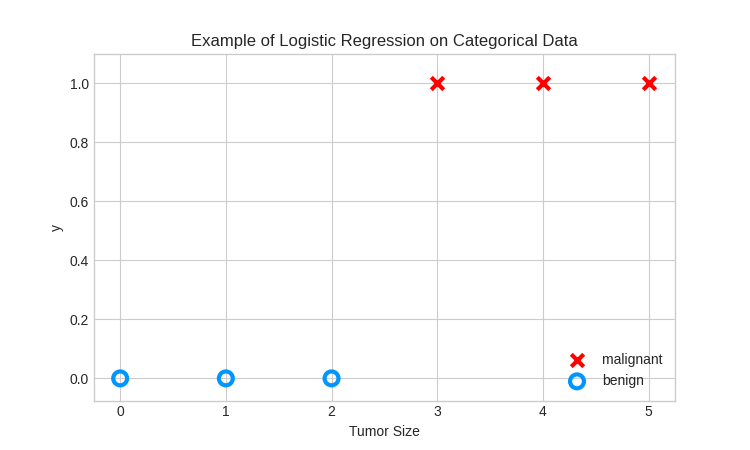

In [10]:
fig, ax = plt.subplots(1, 1, figsize=(7.5, 4.5))
# the initial values for w and b
w, b = 5, -7

ax.scatter(x_train_1[y_train_1 == 1], y_train_1[y_train_1 == 1], marker='x', s=80, c='red', label="malignant", lw=3)
ax.scatter(x_train_1[y_train_1 == 0], y_train_1[y_train_1 == 0], marker='o', s=100, label="benign",
           facecolors='none', edgecolors='#0096ff', lw=3)
ax.set(ylim=[-0.075, 1.1], ylabel='y', xlabel='Tumor Size')

# start your code here
# color code = FF9300


# end your code here

ax.legend(loc='lower right')
ax.set_title("Example of Logistic Regression on Categorical Data")

plt.show()

## The cost function for logistic regression

Using squared error to form the overall cost function for logistic regression leads to a non-convex cost function:



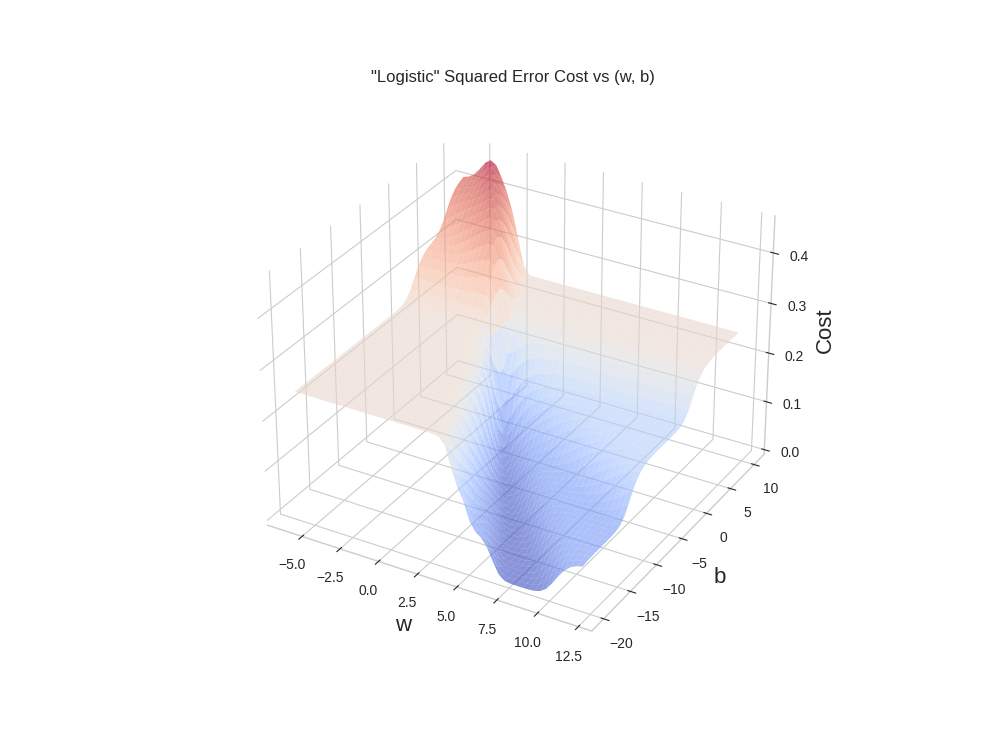

In [11]:
plt_logistic_squared_error(x_train_1, y_train_1)
plt.show()


Logistic Regression uses a loss function more suited to the task of categorization where the target is 0 or 1 rather than any number.

The loss function is called the **cross entropy** loss, and defined as follows:

$$\text{loss}(f_{\mathbf{w},b}(\mathbf{x}^{(i)}), y^{(i)}) = -y^{(i)} \log\left(f_{\mathbf{w},b}\left( \mathbf{x}^{(i)} \right) \right) - \left( 1 - y^{(i)}\right) \log \left( 1 - f_{\mathbf{w},b}\left( \mathbf{x}^{(i)} \right) \right)$$

With this new loss function, a cost function can be produced that incorporates the loss from all the examples:

  $$
  J(\mathbf{w},b) = \frac{1}{m} \sum\limits_{i = 1}^{m} \left[ - y^{(i)} \log\left(f_{\mathbf{w},b}\left( \mathbf{x}^{(i)} \right) \right) - \left( 1 - y^{(i)}\right) \log \left( 1 - f_{\mathbf{w},b}\left( \mathbf{x}^{(i)} \right) \right) \right] \tag{4}
  $$

Let's take a look at the cost vs parameters curve for the simple example we considered above:

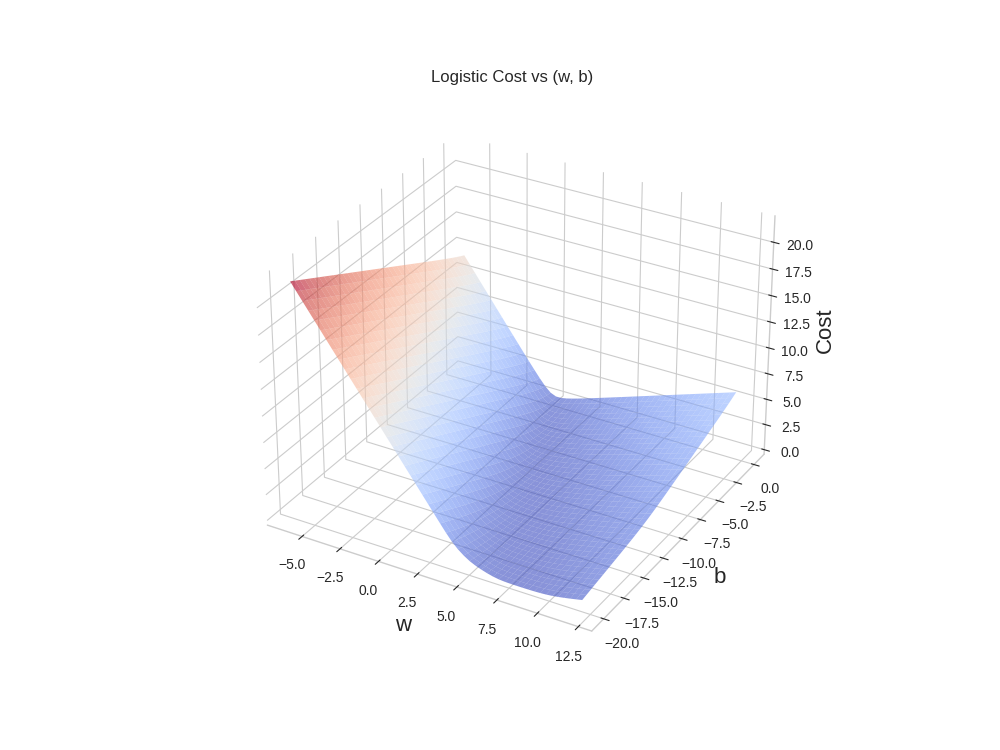

In [12]:
plt_logistic_cost(x_train_1, y_train_1)
plt.show()

This curve is well suited to gradient descent. It does not have plateaus, local minima, or discontinuities.

**<font color='steelblue' > Question 3</font>**:

Complete the following code to define a function named `compute_cost_logistic` for calculating the loss for each example and accumulating the total.

Note that the variables X and y are not scalar values but matrices of shape ($m, n$) and ($𝑚$,) respectively, where  $𝑛$ is the number of features and $𝑚$ is the number of training examples.


In [13]:
def compute_cost_logistic(X, y, w, b):
    """
    Computes cost

    Args:
      X (ndarray (m, n)): Data, m examples with n features
      y (ndarray (m,)) : target values
      w (ndarray (n,)) : model parameters
      b (scalar)       : model parameter

    Returns:
      cost (scalar): cost
    """
    # start your code here



    # end your code here

    return cost


Check the implementation of the cost function using the cell below:

In [ ]:
# a two-feature training set
X_train_2 = np.array([[0.5, 1.5], [1, 1], [1.5, 0.5], [3, 0.5], [2, 2], [1, 2.5]])
y_train_2 = np.array([0, 0, 0, 1, 1, 1])
w_tmp = np.array([1, 1])
b_tmp = -3
print(compute_cost_logistic(X_train_2, y_train_2, w_tmp, b_tmp))

**Expected output**: 0.3668667864055175

## Decision Boundary

Question: Complete the following code to plot the decision boundaries for

-   $b = -3, w_1 = 1, w_2 = 1$;
-   $b = -4, w_1 = 1, w_2 = 1$

In [ ]:
fig, ax = plt.subplots(1,1, figsize=(6, 6))

# find indices of Positive and Negative Examples
pos = y_train_2 == 1
neg = y_train_2 == 0
# work with 1D or 1D y vectors
pos = pos.reshape(-1,)
neg = neg.reshape(-1,)

ax.scatter(X_train_2[pos, 0], X_train_2[pos, 1], marker='x', s=80, c = 'red', label="y = 1", lw=3)
ax.scatter(X_train_2[neg, 0], X_train_2[neg, 1], marker='o', s=100, label="y = 0", facecolors='none', edgecolors='#0096ff', lw=3)
ax.legend(loc='best')

# start your code here
x0 = np.arange(0, 6)
ax.plot(x0, 3-x0, c='#FF9300', label="$b$=-3")
ax.plot(x0, 4-x0, c='magenta', label="$b$=-4")

# end your code here

# set both axes to be from 0-4
ax.axis([0, 4, 0, 3.5])
ax.set_ylabel('$x_1$', fontsize=12)
ax.set_xlabel('$x_0$', fontsize=12)
plt.show()

## Gradient Descent

In the plot below, try:

- changing $w$ and $b$ by clicking within the contour plot on the upper right.
    - changes may take a second or two
    - note the changing value of cost on the upper left plot.
    - note the cost is accumulated by a loss on each example (vertical dotted lines)
- run gradient descent by clicking the orange button.
    - note the steadily decreasing cost
    - clicking in the contour plot will reset the model for a new run
- to reset the plot, rerun the cell

In [ ]:
w_range = np.array([-1, 10])
b_range = np.array([1, -14])
plt.close("all")
quad = plt_quad_logistic(x_train_1, y_train_1, w_range, b_range)